# SPP nonparametric basis sweep

This notebook studies the sensitivity of feature recovery to the number of basis functions used for the interaction kernel and the environment force in the nonparametric formulation. The training data are fixed, and only the approximation spaces are varied.

For each pair \((n_\phi,n_f)\), we fit a nonparametric model, save the fit artifact, reload the learned model, and evaluate the relative kernel error \(E_\phi^{\mathrm{rel}}\) and relative environment-force error \(E_f^{\mathrm{rel}}\) on the fixed density-evaluation grids from Stage 2.2b.

All outputs are saved under:

`artifacts/spp/limitation/basis_sweep`.

```
`artifacts/spp/limitation/basis_sweep/
    fits/
    summaries/
        basis_sweep_fit_index.csv
        basis_sweep_feature_errors.csv
        basis_sweep_best_cases.csv
    figures/
        nphi_vs_E_phi_relative.png
        nphi_vs_E_phi_relative.pdf
        nf_vs_E_f_relative.png
        nf_vs_E_f_relative.pdf
        heatmap_E_phi_relative.png
        heatmap_E_phi_relative.pdf
        heatmap_E_f_relative.png
        heatmap_E_f_relative.pdf
        heatmap_E_total_relative.png
        heatmap_E_total_relative.pdf```

## Interpretation

This experiment is intended to support the basis-selection and limitation discussion. Small basis sizes are expected to underfit either the interaction kernel or the environment force. Increasing the basis size should reduce the corresponding feature error until the approximation saturates. If the basis is too large relative to the fixed training data, conditioning may deteriorate, and the feature error may stagnate or increase.

This limitation study separates approximation effects from data effects because all fits use the same training data and the same evaluation grids.

In [2]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import os

def find_project_root(start: Path) -> Path:
    current = start.resolve()

    while current != current.parent:
        if (current / "src").exists() and (current / "artifacts").exists():
            return current
        if (current / "src").exists():
            return current
        current = current.parent

    raise RuntimeError("Could not locate project root containing src/")


PROJECT_ROOT = find_project_root(Path.cwd())

SRC = PROJECT_ROOT / "src"
ARTIFACTS = PROJECT_ROOT / "artifacts"

if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

print("PROJECT_ROOT:", PROJECT_ROOT)
print("SRC:", SRC)
print("ARTIFACTS:", ARTIFACTS)


#-------------------
# Change working directory to project root
os.chdir(PROJECT_ROOT)
print("CWD:", Path.cwd())

PROJECT_ROOT: .
SRC: ./src
ARTIFACTS: ./artifacts
CWD: .


In [3]:
SYSTEM_NAME = "spp"

# Canonical SPP data used by the main SPP experiment.
DATA_PROFILE_NAME = "spp_velocity_grid_clumps"

# Output namespace for this limitation experiment.
PROFILE_NAME = "limitation"
TASK_NAME = "basis_sweep"
SWEEP_PROFILE_NAME = f"{PROFILE_NAME}/{TASK_NAME}"


SWEEP_DIR = ARTIFACTS / SYSTEM_NAME / PROFILE_NAME / TASK_NAME
FIT_DIR = SWEEP_DIR / "fits"
SUMMARY_DIR = SWEEP_DIR / "summaries"
FIGURE_DIR = SWEEP_DIR / "figures"

for p in [SWEEP_DIR, FIT_DIR, SUMMARY_DIR, FIGURE_DIR]:
    p.mkdir(parents=True, exist_ok=True)

TRAIN_FIT_SPLIT = "train_fit"
TRAIN_FIT_DATASET_NAME = "dataset_train_fit_trial_001"

FEATURE_NAME = TRAIN_FIT_DATASET_NAME
SOURCE_BASIS_NAME = TRAIN_FIT_DATASET_NAME

ALGORITHM = "nonparametric_f"
INTERACTION_TYPE = "energy"

RIDGE_LAMBDA = 1e-8
SVD_TOL = 1e-12

# Choose your sweep values
N_PHI_LIST = [4, 6, 8, 10, 12, 15, 20, 30]
N_F_LIST = [4, 6, 8, 10, 12, 15, 20, 30]

In [4]:
from ips_learning.data.dataset_repository import DatasetRepository
from ips_learning.features.feature_builder import FeatureBuilder
from ips_learning.features.feature_repository import FeatureRepository

from ips_learning.bases.specs import (
    BasisConfig,
    RadialBasisSpec,
    EnvironmentBasisSpec,
)
from ips_learning.bases.builders import BasisBuilder
from ips_learning.bases.repository import BasisRepository

from ips_learning.fitting.assembler import NormalEquationAssembler
from ips_learning.fitting.solver import LinearSystemSolver
from ips_learning.fitting.system_repository import NormalSystemRepository

from ips_learning.models.factories import LearnedModelFactory
from ips_learning.evaluation.function_errors import (
    KernelErrorEvaluator,
    EnvironmentErrorEvaluator,
)

from ips_learning.statistics.density import build_empirical_error_density

from ips_learning.systems.spp import SPPSystem

## Load data and features

In [ ]:
dataset_repo = DatasetRepository(root_dir=ARTIFACTS / "datasets")
feature_repo = FeatureRepository(root_dir=ARTIFACTS / "features")
basis_repo = BasisRepository(root_dir=ARTIFACTS / "bases")
fit_repo = NormalSystemRepository(root_dir=ARTIFACTS / "fits")

train_fit_dataset = dataset_repo.load(
    system_name=SYSTEM_NAME,
    profile_name=DATA_PROFILE_NAME,
    split=TRAIN_FIT_SPLIT,
    dataset_name=TRAIN_FIT_DATASET_NAME,
)

features = feature_repo.load(
    system_name=SYSTEM_NAME,
    profile_name=DATA_PROFILE_NAME,
    split=TRAIN_FIT_SPLIT,
    feature_name=FEATURE_NAME,
)

# Use the canonical SPP basis artifact only for the localization/support
# metadata defining the fixed empirical-error evaluation grids.
source_basis_bundle = basis_repo.load(
    system_name=SYSTEM_NAME,
    profile_name=DATA_PROFILE_NAME,
    split=TRAIN_FIT_SPLIT,
    basis_name=SOURCE_BASIS_NAME,
)

N = int(train_fit_dataset.metadata["N"])
D = int(train_fit_dataset.metadata["D"])

true_system = SPPSystem(N=N, D=D)

true_kernel = true_system.kernel
true_env = true_system.f_env

print("Source data profile:", DATA_PROFILE_NAME)
print("Sweep profile:", SWEEP_PROFILE_NAME)
print("N, D:", N, D)


## Load density-evaluation grids

In [ ]:
# Fixed empirical measure used for every basis-sweep case.
#
# This is constructed from the same canonical train_fit data used for
# learning. It is intentionally independent of (n_phi, n_f), so changes
# in reported feature errors reflect basis resolution rather than changes
# in the weighting measure.

empirical_density = build_empirical_error_density(
    features=features,
    localization_metadata=source_basis_bundle.localization_metadata,
)

r_grid = empirical_density.r_grid
rho_R = empirical_density.kernel_weights

z1_grid = empirical_density.z1_grid
z2_grid = empirical_density.z2_grid
rho_Z = empirical_density.environment_weights

print("r_grid:", r_grid.shape)
print("rho_R:", rho_R.shape)
print("z1_grid:", z1_grid.shape)
print("z2_grid:", None if z2_grid is None else z2_grid.shape)
print("rho_Z:", rho_Z.shape)


## Fit one basis pair

In [7]:
def basis_case_name(n_phi: int, n_f: int) -> str:
    return f"nphi_{n_phi:03d}_nf_{n_f:03d}"


def build_basis_bundle(n_phi: int, n_f: int):
    basis_config = BasisConfig(
        radial=RadialBasisSpec(
            family="bspline",
            degree=1,
            n_basis=n_phi,
        ),
        environment=EnvironmentBasisSpec(
            family="bspline",
            degree=1,
            n_basis_per_dim=n_f,
        ),
    )

    basis_builder = BasisBuilder(basis_config)
    return basis_builder.build(features=features)


def fit_basis_pair(n_phi: int, n_f: int):
    case_name = basis_case_name(n_phi, n_f)
    basis_name = f"{TRAIN_FIT_DATASET_NAME}_{case_name}"

    basis_bundle = build_basis_bundle(n_phi, n_f)

    basis_repo.save(
        basis_bundle=basis_bundle,
        system_name=SYSTEM_NAME,
        profile_name=SWEEP_PROFILE_NAME,
        split=TRAIN_FIT_SPLIT,
        basis_name=basis_name,
        overwrite=True,
    )

    solver = LinearSystemSolver(
        method="lstsq",
        ridge_lambda=RIDGE_LAMBDA,
        svd_tol=SVD_TOL,
    )

    assembler = NormalEquationAssembler(
        interaction_type=INTERACTION_TYPE,
        algorithm=ALGORITHM,
    )

    fit_result = assembler.fit(
        features=features,
        basis_bundle=basis_bundle,
        solver=solver,
        system_name=SYSTEM_NAME,
    )

    fit_result.metadata.update(
        {
            "system_name": SYSTEM_NAME,
            "profile_name": SWEEP_PROFILE_NAME,
            "data_profile_name": DATA_PROFILE_NAME,
            "task_name": TASK_NAME,
            "case_name": case_name,
            "algorithm": ALGORITHM,
            "n_phi": n_phi,
            "n_f_per_dim": n_f,
            "n_f_total": n_f ** D,
            "basis_name": basis_name,
            "train_fit_dataset": TRAIN_FIT_DATASET_NAME,
            "feature_name": FEATURE_NAME,
        }
    )

    # Save through repository if available.
    fit_repo.save_fit_result(
        system_name=SYSTEM_NAME,
        profile_name=SWEEP_PROFILE_NAME,
        algorithm=ALGORITHM,
        fit_case_name=case_name,
        fit_result=fit_result,
        overwrite=True,
    )

    # Also save a simple local marker metadata file.
    case_dir = FIT_DIR / case_name
    case_dir.mkdir(parents=True, exist_ok=True)

    with open(case_dir / "metadata.json", "w") as f:
        json.dump(fit_result.metadata, f, indent=2)

    return fit_result, basis_bundle

## Run the full basis sweep and save fits

In [8]:
fit_index_rows = []

for n_phi in N_PHI_LIST:
    for n_f in N_F_LIST:
        case_name = basis_case_name(n_phi, n_f)

        print(f"Fitting {case_name} ...")

        fit_result, basis_bundle = fit_basis_pair(n_phi, n_f)

        fit_index_rows.append(
            {
                "case_name": case_name,
                "n_phi": n_phi,
                "n_f_per_dim": n_f,
                "n_f_total": n_f ** D,
                "condition_number": fit_result.diagnostics.condition_number,
                "rank": fit_result.diagnostics.rank,
                "min_singular": fit_result.diagnostics.min_singular,
                "max_singular": fit_result.diagnostics.max_singular,
            }
        )

fit_index_df = pd.DataFrame(fit_index_rows)
fit_index_path = SUMMARY_DIR / "basis_sweep_fit_index.csv"
fit_index_df.to_csv(fit_index_path, index=False)

fit_index_df

Fitting nphi_004_nf_004 ...
Fitting nphi_004_nf_006 ...
Fitting nphi_004_nf_008 ...
Fitting nphi_004_nf_010 ...
Fitting nphi_004_nf_012 ...
Fitting nphi_004_nf_015 ...
Fitting nphi_004_nf_020 ...
Fitting nphi_004_nf_030 ...
Fitting nphi_006_nf_004 ...
Fitting nphi_006_nf_006 ...
Fitting nphi_006_nf_008 ...
Fitting nphi_006_nf_010 ...
Fitting nphi_006_nf_012 ...
Fitting nphi_006_nf_015 ...
Fitting nphi_006_nf_020 ...
Fitting nphi_006_nf_030 ...
Fitting nphi_008_nf_004 ...
Fitting nphi_008_nf_006 ...
Fitting nphi_008_nf_008 ...
Fitting nphi_008_nf_010 ...
Fitting nphi_008_nf_012 ...
Fitting nphi_008_nf_015 ...
Fitting nphi_008_nf_020 ...
Fitting nphi_008_nf_030 ...
Fitting nphi_010_nf_004 ...
Fitting nphi_010_nf_006 ...
Fitting nphi_010_nf_008 ...
Fitting nphi_010_nf_010 ...
Fitting nphi_010_nf_012 ...
Fitting nphi_010_nf_015 ...
Fitting nphi_010_nf_020 ...
Fitting nphi_010_nf_030 ...
Fitting nphi_012_nf_004 ...
Fitting nphi_012_nf_006 ...
Fitting nphi_012_nf_008 ...
Fitting nphi_012_nf_

,case_name,n_phi,n_f_per_dim,n_f_total,condition_number,rank,min_singular,max_singular
0,nphi_004_nf_004,4,4,16,2.709903e+03,36,8.388604e-04,2.273231
1,nphi_004_nf_006,4,6,36,1.057259e+04,76,2.149327e-04,2.272396
2,nphi_004_nf_008,4,8,64,2.383652e+04,132,9.532626e-05,2.272247
3,nphi_004_nf_010,4,10,100,6.232397e+04,204,3.645299e-05,2.271895
4,nphi_004_nf_012,4,12,144,1.723207e+05,292,1.318417e-05,2.271905
...,...,...,...,...,...,...,...,...
59,nphi_030_nf_010,30,10,100,3.511865e+04,230,8.737881e-06,0.306863
60,nphi_030_nf_012,30,12,144,3.586067e+04,318,8.557593e-06,0.306881
61,nphi_030_nf_015,30,15,225,6.356172e+04,480,4.824735e-06,0.306668
62,nphi_030_nf_020,30,20,400,1.469939e+07,830,2.084951e-08,0.306475


## Reload fits and calculate errors

In [9]:
kernel_error_evaluator = KernelErrorEvaluator()
environment_error_evaluator = EnvironmentErrorEvaluator()


def load_fit_and_basis(n_phi: int, n_f: int):
    case_name = basis_case_name(n_phi, n_f)
    basis_name = f"{TRAIN_FIT_DATASET_NAME}_{case_name}"

    fit_result = fit_repo.load_fit_result(
        system_name=SYSTEM_NAME,
        profile_name=SWEEP_PROFILE_NAME,
        algorithm=ALGORITHM,
        fit_case_name=case_name,
    )

    basis_bundle = basis_repo.load(
        system_name=SYSTEM_NAME,
        profile_name=SWEEP_PROFILE_NAME,
        split=TRAIN_FIT_SPLIT,
        basis_name=basis_name,
    )

    learned_model = LearnedModelFactory().build_from_fit_result(
        fit_result=fit_result,
        N=N,
        D=D,
    )

    return fit_result, basis_bundle, learned_model


error_rows = []

for n_phi in N_PHI_LIST:
    for n_f in N_F_LIST:
        case_name = basis_case_name(n_phi, n_f)

        print(f"Evaluating {case_name} ...")

        fit_result, basis_bundle, learned_model = load_fit_and_basis(n_phi, n_f)

        phi_error = kernel_error_evaluator.evaluate(
            true_kernel=true_kernel,
            learned_kernel=learned_model.learned_kernel,
            r_grid=r_grid,
            weights=rho_R,
            include_radial_measure=True,
        )

        f_error = environment_error_evaluator.evaluate(
            true_env=true_env,
            learned_env=learned_model.learned_environment,
            z1_grid=z1_grid,
            z2_grid=z2_grid,
            weights=rho_Z,
        )

        error_rows.append(
            {
                "case_name": case_name,
                "n_phi": n_phi,
                "n_f_per_dim": n_f,
                "n_f_total": n_f ** D,

                "E_phi": phi_error["E_phi"],
                "E_phi_relative": phi_error["E_phi_relative"],

                "E_f": f_error["E_env"],
                "E_f_relative": f_error["E_env_relative"],

                "condition_number": fit_result.diagnostics.condition_number,
                "rank": fit_result.diagnostics.rank,
                "min_singular": fit_result.diagnostics.min_singular,
                "max_singular": fit_result.diagnostics.max_singular,
            }
        )

basis_sweep_errors = pd.DataFrame(error_rows)

error_csv = SUMMARY_DIR / "basis_sweep_feature_errors.csv"
basis_sweep_errors.to_csv(error_csv, index=False)

basis_sweep_errors

Evaluating nphi_004_nf_004 ...
Evaluating nphi_004_nf_006 ...
Evaluating nphi_004_nf_008 ...
Evaluating nphi_004_nf_010 ...
Evaluating nphi_004_nf_012 ...
Evaluating nphi_004_nf_015 ...
Evaluating nphi_004_nf_020 ...
Evaluating nphi_004_nf_030 ...
Evaluating nphi_006_nf_004 ...
Evaluating nphi_006_nf_006 ...
Evaluating nphi_006_nf_008 ...
Evaluating nphi_006_nf_010 ...
Evaluating nphi_006_nf_012 ...
Evaluating nphi_006_nf_015 ...
Evaluating nphi_006_nf_020 ...
Evaluating nphi_006_nf_030 ...
Evaluating nphi_008_nf_004 ...
Evaluating nphi_008_nf_006 ...
Evaluating nphi_008_nf_008 ...
Evaluating nphi_008_nf_010 ...
Evaluating nphi_008_nf_012 ...
Evaluating nphi_008_nf_015 ...
Evaluating nphi_008_nf_020 ...
Evaluating nphi_008_nf_030 ...
Evaluating nphi_010_nf_004 ...
Evaluating nphi_010_nf_006 ...
Evaluating nphi_010_nf_008 ...
Evaluating nphi_010_nf_010 ...
Evaluating nphi_010_nf_012 ...
Evaluating nphi_010_nf_015 ...
Evaluating nphi_010_nf_020 ...
Evaluating nphi_010_nf_030 ...
Evaluati

,case_name,n_phi,n_f_per_dim,n_f_total,E_phi,E_phi_relative,E_f,E_f_relative,condition_number,rank,min_singular,max_singular
0,nphi_004_nf_004,4,4,16,0.466887,0.409661,0.657264,0.222154,2.709903e+03,36,8.388604e-04,2.273231
1,nphi_004_nf_006,4,6,36,0.464142,0.407252,0.268913,0.090892,1.057259e+04,76,2.149327e-04,2.272396
2,nphi_004_nf_008,4,8,64,0.467262,0.409990,0.152392,0.051508,2.383652e+04,132,9.532626e-05,2.272247
3,nphi_004_nf_010,4,10,100,0.467110,0.409856,0.099771,0.033722,6.232397e+04,204,3.645299e-05,2.271895
4,nphi_004_nf_012,4,12,144,0.467071,0.409822,0.081915,0.027687,1.723207e+05,292,1.318417e-05,2.271905
...,...,...,...,...,...,...,...,...,...,...,...,...
59,nphi_030_nf_010,30,10,100,0.046251,0.040582,0.086842,0.029352,3.511865e+04,230,8.737881e-06,0.306863
60,nphi_030_nf_012,30,12,144,0.043869,0.038492,0.058268,0.019695,3.586067e+04,318,8.557593e-06,0.306881
61,nphi_030_nf_015,30,15,225,0.041006,0.035980,0.037302,0.012608,6.356172e+04,480,4.824735e-06,0.306668
62,nphi_030_nf_020,30,20,400,0.040374,0.035425,0.022072,0.007460,1.469939e+07,830,2.084951e-08,0.306475


In [10]:
from matplotlib import pyplot as plt

In [11]:
def plot_heatmap(df, value_col, title, output_stem):
    pivot = df.pivot(
        index="n_f_per_dim",
        columns="n_phi",
        values=value_col,
    )

    x_vals = pivot.columns.to_numpy()
    y_vals = pivot.index.to_numpy()
    Z = pivot.to_numpy()

    fig, ax = plt.subplots(figsize=(7.0, 5.6))

    im = ax.imshow(
        Z,
        origin="lower",
        aspect="auto",
        extent=[
            x_vals.min(),
            x_vals.max(),
            y_vals.min(),
            y_vals.max(),
        ],
    )

    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label(value_col)

    ax.set_xlabel(r"$n_{\phi}$")
    ax.set_ylabel(r"$n_f$ per dimension")
    ax.set_title(title)

    ax.set_xticks(x_vals)
    ax.set_yticks(y_vals)

    fig.savefig(FIGURE_DIR / f"{output_stem}.png", dpi=300)
    fig.savefig(FIGURE_DIR / f"{output_stem}.pdf")

    return fig

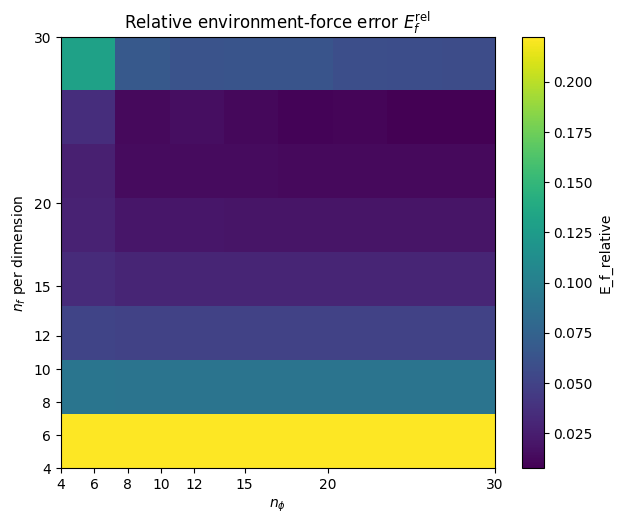

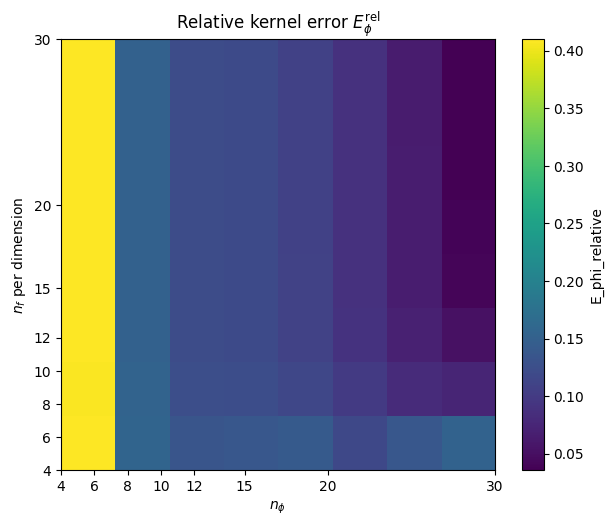

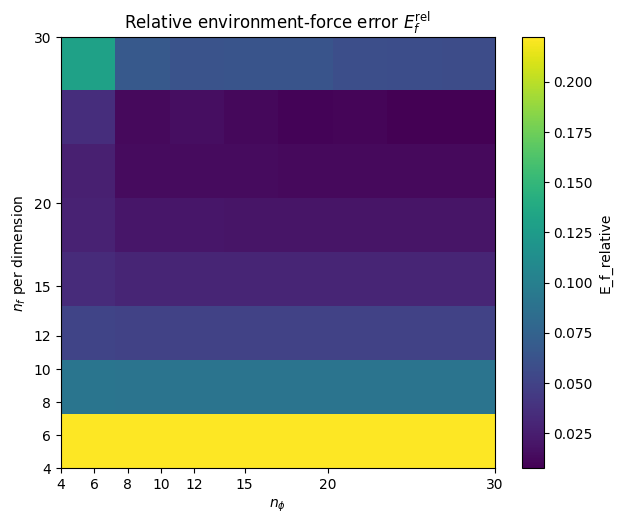

In [12]:
plot_heatmap(
    basis_sweep_errors,
    value_col="E_phi_relative",
    title=r"Relative kernel error $E_{\phi}^{\mathrm{rel}}$",
    output_stem="heatmap_E_phi_relative",
)

plot_heatmap(
    basis_sweep_errors,
    value_col="E_f_relative",
    title=r"Relative environment-force error $E_f^{\mathrm{rel}}$",
    output_stem="heatmap_E_f_relative",
)

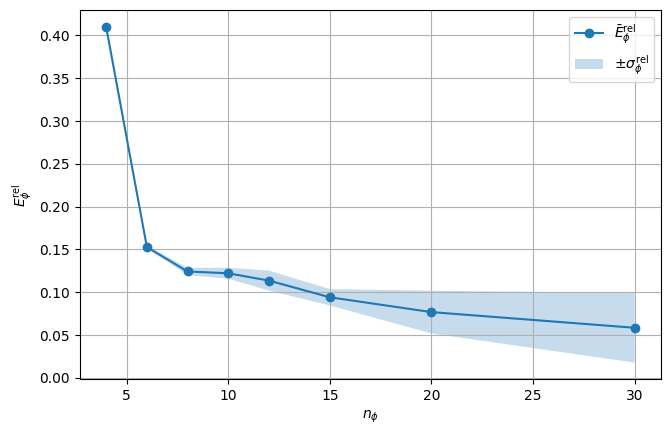

In [15]:
phi_curve = (
    basis_sweep_errors
    .groupby("n_phi")["E_phi_relative"]
    .agg(["mean", "std"])
    .reset_index()
)

fig, ax = plt.subplots(figsize=(7.5, 4.8))

ax.plot(
    phi_curve["n_phi"],
    phi_curve["mean"],
    marker="o",
    label=r"$\bar{E}_{\phi}^{\mathrm{rel}}$",
)

ax.fill_between(
    phi_curve["n_phi"],
    phi_curve["mean"] - phi_curve["std"],
    phi_curve["mean"] + phi_curve["std"],
    alpha=0.25,
    label=r"$\pm \sigma_{\phi}^{\mathrm{rel}}$",
)
ax.grid(True)
ax.set_xlabel(r"$n_{\phi}$")
ax.set_ylabel(r"$E_{\phi}^{\mathrm{rel}}$")
ax.legend()
fig.savefig(FIGURE_DIR / "nphi_vs_E_phi_relative.png", dpi=300)
fig.savefig(FIGURE_DIR / "nphi_vs_E_phi_relative.pdf")

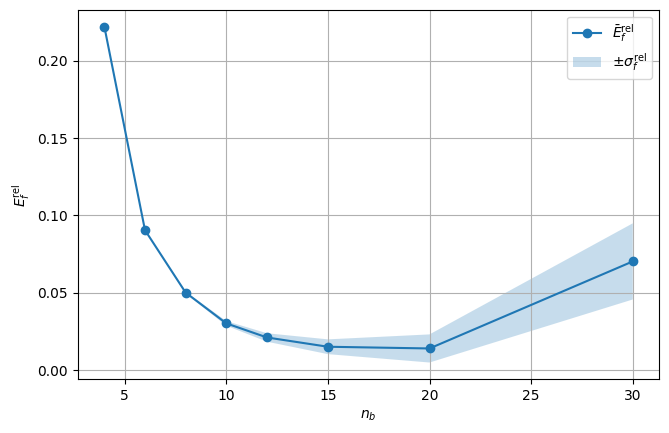

In [17]:
f_curve = (
    basis_sweep_errors
    .groupby("n_f_per_dim")["E_f_relative"]
    .agg(["mean", "std"])
    .reset_index()
)

fig, ax = plt.subplots(figsize=(7.5, 4.8))

ax.plot(
    f_curve["n_f_per_dim"],
    f_curve["mean"],
    marker="o",
    label=r"$\bar{E}_{f}^{\mathrm{rel}}$"
)

ax.fill_between(
    f_curve["n_f_per_dim"],
    f_curve["mean"] - f_curve["std"],
    f_curve["mean"] + f_curve["std"],
    alpha=0.25,
    label=r"$\pm \sigma_{f}^{\mathrm{rel}}$",
)
ax.grid(True)
ax.set_xlabel(r"$n_b$")
ax.set_ylabel(r"$E_f^{\mathrm{rel}}$")
ax.legend()
fig.savefig(FIGURE_DIR / "nf_vs_E_f_relative.png", dpi=300)
fig.savefig(FIGURE_DIR / "nf_vs_E_f_relative.pdf")

Kernel recovery saturates once n
ϕ
	​

≥10, whereas increasing n
f
	​

 beyond 8 produces negligible improvement in environment-force recovery.